### This notebook includes the basic joint GCS and PCS using Gumbel-softmax differentiable sampling technique. Initialization with a known constellation is required when bit metric decoding is used. In this notebook we add phase noise impairment and enable training.

In [1]:
%reset

In [1]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import Model
from tensorflow.keras.layers import Layer, Dense
from tensorflow.nn import relu
from tensorflow.keras.losses import BinaryCrossentropy
from sionna.phy.block import Block
from sionna.phy.utils import expand_to_rank, hard_decisions
import importlib
import pn_classes
importlib.reload(pn_classes)
from pn_classes import PhaseNoise, PN_Compensation, PTRS_Adder
import sionna as sn
import matplotlib.pyplot as plt
import os
import gc

2026-02-25 14:20:40.529892: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1772022040.541875    7994 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1772022040.545745    7994 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1772022040.554837    7994 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1772022040.554849    7994 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1772022040.554851    7994 computation_placer.cc:177] computation placer alr

In [2]:
devices = tf.config.list_physical_devices('GPU')
print(len(devices))

1


In [3]:
symbol_points_qam64 = np.array([-1.08012344973464 + 1.08012344973464j
,-1.08012344973464 + 0.771516749810460j
,-1.08012344973464 + 0.154303349962092j
,-1.08012344973464 + 0.462910049886276j
,-0.771516749810460 + 1.08012344973464j
,-0.771516749810460 + 0.771516749810460j
,-0.771516749810460 + 0.154303349962092j
,-0.771516749810460 + 0.462910049886276j
,-0.154303349962092 + 1.08012344973464j
,-0.154303349962092 + 0.771516749810460j
,-0.154303349962092 + 0.154303349962092j
,-0.154303349962092 + 0.462910049886276j
,-0.462910049886276 + 1.08012344973464j
,-0.462910049886276 + 0.771516749810460j
,-0.462910049886276 + 0.154303349962092j
,-0.462910049886276 + 0.462910049886276j
,-1.08012344973464 - 1.08012344973464j
,-1.08012344973464 - 0.771516749810460j
,-1.08012344973464 - 0.154303349962092j
,-1.08012344973464 - 0.462910049886276j
,-0.771516749810460 - 1.08012344973464j
,-0.771516749810460 - 0.771516749810460j
,-0.771516749810460 - 0.154303349962092j
,-0.771516749810460 - 0.462910049886276j
,-0.154303349962092 - 1.08012344973464j
,-0.154303349962092 - 0.771516749810460j
,-0.154303349962092 - 0.154303349962092j
,-0.154303349962092 - 0.462910049886276j
,-0.462910049886276 - 1.08012344973464j
,-0.462910049886276 - 0.771516749810460j
,-0.462910049886276 - 0.154303349962092j
,-0.462910049886276 - 0.462910049886276j
,1.08012344973464 + 1.08012344973464j
,1.08012344973464 + 0.771516749810460j
,1.08012344973464 + 0.154303349962092j
,1.08012344973464 + 0.462910049886276j
,0.771516749810460 + 1.08012344973464j
,0.771516749810460 + 0.771516749810460j
,0.771516749810460 + 0.154303349962092j
,0.771516749810460 + 0.462910049886276j
,0.154303349962092 + 1.08012344973464j
,0.154303349962092 + 0.771516749810460j
,0.154303349962092 + 0.154303349962092j
,0.154303349962092 + 0.462910049886276j
,0.462910049886276 + 1.08012344973464j
,0.462910049886276 + 0.771516749810460j
,0.462910049886276 + 0.154303349962092j
,0.462910049886276 + 0.462910049886276j
,1.08012344973464 - 1.08012344973464j
,1.08012344973464 - 0.771516749810460j
,1.08012344973464 - 0.154303349962092j
,1.08012344973464 - 0.462910049886276j
,0.771516749810460 - 1.08012344973464j
,0.771516749810460 - 0.771516749810460j
,0.771516749810460 - 0.154303349962092j
,0.771516749810460 - 0.462910049886276j
,0.154303349962092 - 1.08012344973464j
,0.154303349962092 - 0.771516749810460j
,0.154303349962092 - 0.154303349962092j
,0.154303349962092 - 0.462910049886276j
,0.462910049886276 - 1.08012344973464j
,0.462910049886276 - 0.771516749810460j
,0.462910049886276 - 0.154303349962092j
,0.462910049886276 - 0.462910049886276j])

In [4]:
def normalize_constellation(points, probabilities):

    # Compute the power of the constellation
    power = np.sum(probabilities * np.abs(points)**2)
    # Normalize the constellation points
    normalized_points = points / np.sqrt(power)
    return normalized_points

def plot_constellation_wlabels(points, probabilities, plot_title):

    points = np.asarray(points)
    probabilities = np.asarray(probabilities).flatten()

    # Scale marker sizes for visibility
    marker_sizes = 300 * probabilities / max(probabilities)

    plt.figure(figsize=(8, 8))
    plt.scatter(points.real, points.imag, s=marker_sizes, alpha=0.7, c='b', edgecolors='k')

    # Annotate with 6-bit binary labels
    for i, pt in enumerate(points):
        label = format(i, '06b')  # 6-bit binary string
        plt.text(pt.real + 0.05, pt.imag + 0.05, label, fontsize=9, ha='left', va='bottom', color='darkred')

    # Add grid and formatting
    plt.axhline(0, color='gray', linewidth=0.5, linestyle='--')
    plt.axvline(0, color='gray', linewidth=0.5, linestyle='--')
    plt.grid(True, linestyle=':')
    plt.xlabel("In-phase")
    plt.ylabel("Quadrature")
    plt.title(plot_title)
    plt.gca().set_aspect('equal', adjustable='box')
    plt.tight_layout()
    # plt.show()


In [5]:
class Modulator(Layer):

    def __init__(self, constellation, N,  parity_k, **kwargs):
        super(Modulator, self).__init__(**kwargs)

        # Define the real and imaginary parts of the constellation as trainable variables
        # self.constellation_real = tf.Variable(constellation.real, dtype=tf.float32, trainable=True)
        # self.constellation_imag = tf.Variable(constellation.imag, dtype=tf.float32, trainable=True)
        self.constellation_real_init = constellation.real
        self.constellation_imag_init = constellation.imag
        self.parity_k = parity_k
        self.N = N

    def build(self, input_shape):
        self.constellation_real = self.add_weight(
            name="constellation_real",
            shape=self.constellation_real_init.shape,
            initializer=tf.constant_initializer(self.constellation_real_init),
            trainable=True
        )
        self.constellation_imag = self.add_weight(
            name="constellation_imag",
            shape=self.constellation_imag_init.shape,
            initializer=tf.constant_initializer(self.constellation_imag_init),
            trainable=True
        )

    def call(self, s, probabilities):
        # Combine the real and imaginary parts into a complex-valued constellation
        constellation_combined = tf.complex(self.constellation_real, self.constellation_imag)

        # Expand the signal dimension to align for matrix multiplication
        s = tf.expand_dims(s, axis=-1)

        # Normalize the constellation
        normalization_constants = tf.sqrt(
            tf.reduce_sum(tf.reshape((2**parity_k)*probabilities * tf.abs(constellation_combined) ** 2,(1,(2**self.parity_k),int(self.N/(2**self.parity_k)))), 2)
        )
        normalization_constants = tf.expand_dims(normalization_constants, axis=2)
        normalization_constants = tf.complex(tf.reshape(tf.tile(normalization_constants,(1,1,int(self.N/(2**self.parity_k)))),(1,self.N)),0.0)
        norm_constellation = constellation_combined / normalization_constants

        # print('norm_constellation',norm_constellation.shape)
        # print('s',s.shape)
        # Compute the modulated signal
        x_real = tf.matmul(tf.math.real(norm_constellation), s)
        x_imag = tf.matmul(tf.math.imag(norm_constellation), s)
        x = tf.complex(x_real, x_imag)

        return tf.squeeze(x, axis=[-1, -2]), norm_constellation

In [6]:
class Demodulator_bitwise(Layer):
    def __init__(self, bits_per_symbol):
        super(Demodulator_bitwise, self).__init__()
        self.dense1 = Dense(128, activation='relu')  # First Dense Layer
        self.dense2 = Dense(128, activation='relu')  # Second Dense Layer
        self.dense3 = Dense(bits_per_symbol, activation='sigmoid')                      # Output Dense Layer
        # self.snr_db = snr_db                        # SNR in dB

    def call(self, y, batch_size, block_size):
        # Ensure complex-valued input is split into real and imaginary parts
        y_real = tf.math.real(y)
        y_imag = tf.math.imag(y)

        # Create and broadcast SNR tensor
        snr_tensor = tf.constant([[1]], dtype=tf.float32)
        brd_snr_tensor = tf.broadcast_to(snr_tensor, [batch_size, block_size, 1])

        # Concatenate real, imaginary, and SNR tensors along the last dimension
        y_real = tf.expand_dims(y_real,axis=-1)
        y_imag = tf.expand_dims(y_imag,axis=-1)
        # print('y_real',y_real.shape)
        # print('y_imag',y_imag.shape)
        # print('brd_snr_tensor',brd_snr_tensor.shape)
        stack_input = tf.concat([y_real, y_imag, brd_snr_tensor], axis=2)

        ## print('brd_snr_tensor.shape: ',brd_snr_tensor)

        # Pass the stacked input through the dense layers
        x = self.dense1(stack_input)
        x = self.dense2(x)
        logits = self.dense3(x)

        return logits

In [7]:
class SymbolLogits2LLRs_Prob_Aware(Block):

    def __init__(self,
                 method,
                 num_bits_per_symbol,
                 *,
                 hard_out=False,
                 precision=None,
                 **kwargs):
        super().__init__(precision=precision, **kwargs)
        assert method in ("app","maxlog"), "Unknown demapping method"
        self._method = method
        self._hard_out = hard_out
        self._num_bits_per_symbol = num_bits_per_symbol
        num_points = int(2**num_bits_per_symbol)
        a = np.zeros([num_points, num_bits_per_symbol])
        for i in range(0, num_points):
            a[i,:] = np.array(list(np.binary_repr(i, num_bits_per_symbol)),
                              dtype=np.int32)
        c0 = np.zeros([int(num_points/2), num_bits_per_symbol])
        c1 = np.zeros([int(num_points/2), num_bits_per_symbol])
        for i in range(num_bits_per_symbol-1,-1,-1):
            c0[:,i] = np.where(a[:,i]==0)[0]
            c1[:,i] = np.where(a[:,i]==1)[0]
        self._c0 = tf.constant(c0, dtype=tf.int32) # Symbols with ith bit=0
        self._c1 = tf.constant(c1, dtype=tf.int32) # Symbols with ith bit=1
        a = 2*a-1
        self._a = tf.constant(a, dtype=self.rdtype)
        if self._method == "app":
            self._reduce = tf.reduce_logsumexp
        else:
            self._reduce = tf.reduce_max

    @property
    def num_bits_per_symbol(self):
        """
        `int` : Number of bits per symbol
        """
        return self._num_bits_per_symbol

    def call(self, logits, probabilities):
        # Compute exponents
        exponents = logits
        exp0 = tf.gather(exponents, self._c0, axis=-1, batch_dims=0)
        exp1 = tf.gather(exponents, self._c1, axis=-1, batch_dims=0)
        exp_ps = expand_to_rank(tf.math.log(probabilities), tf.rank(logits), axis=0)
        exp_ps0 = tf.gather(exp_ps, self._c0, axis=-1)
        exp_ps1 = tf.gather(exp_ps, self._c1, axis=-1)
        llr = self._reduce(exp_ps1 + exp1, axis=-2)\
                - self._reduce(exp_ps0 + exp0, axis=-2)
        if self._hard_out:
            return hard_decisions(llr)
        else:
            return llr

class Demapper_Prob_Aware(Block):
    # pylint: disable=line-too-long

    def __init__(self,
                 demapping_method,
                 num_bits_per_symbol=None,
                 hard_out=False,
                 precision=None,
                 **kwargs):
        super().__init__(precision=precision, **kwargs)

        self._logits2llrs = SymbolLogits2LLRs_Prob_Aware(demapping_method,
                                              num_bits_per_symbol,
                                              hard_out=hard_out,
                                              precision=precision,
                                              **kwargs)

        self._no_threshold = tf.cast(np.finfo(self.rdtype.as_numpy_dtype).tiny,
                                     self.rdtype)

    def call(self, y, no, points, probabilities):

        squared_dist = tf.pow(tf.abs(tf.expand_dims(y, axis=-1) - points), 2)
        no = tf.expand_dims(no, axis=-1)
        no = tf.math.maximum(no, self._no_threshold)
        exponents = -squared_dist/no
        llr = self._logits2llrs(exponents, probabilities)

        return llr

In [8]:
class SamplingMechanism(Layer):
    def __init__(self, N, tau, parity_k):
        super(SamplingMechanism, self).__init__()
        self.dense1 = Dense(128, activation='relu')
        self.dense2 = Dense(int(N/(2**parity_k)), activation=None)
        self.tau = tau
        # self.snr_db = snr_db
        self.parity_k = parity_k
        self.N = N

    def call(self, batch_size, block_size):
        # Create a tensor with the SNR value
        snr_tensor = tf.constant([[1]], dtype=tf.float32)
        # Pass the SNR value through the first dense layer
        a = self.dense1(snr_tensor)

        # Pass through the second dense layer
        logits = self.dense2(a)
        # print('1',logits.shape)
        #
        # Copying the logits 2**parity_k times to constrain according to PAS
        logits = tf.tile(logits, [1, 2**self.parity_k])
        # print('2',logits.shape)

        # Compute softmax output
        softmax_out = tf.nn.softmax(logits, axis=-1)

        logits = tf.expand_dims(logits, axis=1)
        # print('3',logits.shape)
        logits = tf.tile(logits, [batch_size, block_size, 1])

        # Compute Gumbel-Softmax with straight-through sampling
        gumbel_dist = -tf.math.log(-tf.math.log(tf.random.uniform(tf.shape(logits), 0, 1) + 1e-20) + 1e-20)
        gumbel_logits = logits + gumbel_dist
        gumbel_softmax = tf.nn.softmax(gumbel_logits / self.tau, axis=-1)

        max_value = tf.argmax(gumbel_softmax, axis=-1)
        # print(gumbel_softmax.shape)

        # Step 2: Compare each value in gumbel_softmax with the max_value
        hard_sample = tf.one_hot(max_value, depth=self.N, dtype=tf.float32)
        # print("hard_sample:", hard_sample)

        straight_through = gumbel_softmax + tf.stop_gradient(hard_sample - gumbel_softmax)

        return straight_through, softmax_out



In [9]:
class EndToEndSystem_bitwise(Model):
    def __init__(self, N, constellation, papr_batch_size, batch_size, block_size, bits_per_symbol, parity_k, use_upsampling_filtering, tau=1.0):
        super(EndToEndSystem_bitwise, self).__init__()
        # self.No = 1/(10**(snr_db/10))
        # constellation_orig = Constellation("pam", num_bits_per_symbol=6)
        # self.demodulator_map = Demapper_map("app", constellation=constellation_orig)
        self.demodulator = Demapper_Prob_Aware("app",bits_per_symbol)
        self.sampling = SamplingMechanism(N, tau, parity_k)
        self.batch_size = batch_size
        self.block_size = block_size
        self.papr_batch_size = papr_batch_size
        self.modulator = Modulator(constellation,N,parity_k)
        self.channel = sn.phy.channel.AWGN()
        # self.demodulator = Demodulator_bitwise(bits_per_symbol)
        self.loss_fn = BinaryCrossentropy(from_logits=False, reduction='none', axis=[0, 1])
        self.bits_per_symbol = bits_per_symbol
        self.parity_k = parity_k
        self.use_upsampling_filtering = use_upsampling_filtering
        self.upsampler = sn.phy.signal.Upsampling(samples_per_symbol=4)
        self.tx_filter = sn.phy.signal.RootRaisedCosineFilter(beta=0.3,
                                                         samples_per_symbol=4,
                                                         span_in_symbols=32)
        self.rx_filter = sn.phy.signal.RootRaisedCosineFilter(beta=0.3,
                                                         samples_per_symbol=4,
                                                         span_in_symbols=32)

        num_ptrs_blocks = 32
        symbols_per_ptrs_block = 4
        block_size_ptrs = 4096
        bandwidth = 960e3*4096
        fc = 220e9
        samples = 4*(block_size_ptrs+32)

        self.downsampler = sn.phy.signal.Downsampling(samples_per_symbol=4,
                                                      offset = self.rx_filter.length - 1,
                                                 num_symbols=tf.cast(block_size_ptrs, tf.int32))

        path_to_mat = "../PreloadedMats/ptrs_CAZAC_4_32.mat"

        self.ptrs_adder = PTRS_Adder(path_to_mat, num_ptrs_blocks, symbols_per_ptrs_block, block_size_ptrs, batch_size)
        self.pn_compensate = PN_Compensation(self.ptrs_adder.ptrs_indices, self.ptrs_adder.data_indices, block_size_ptrs, self.ptrs_adder.pilots,batch_size)
        self.pn_tx = PhaseNoise(model_type='13', bandwidth=bandwidth, fc=fc, n_samples=samples)
        self.pn_rx = PhaseNoise(model_type='11', bandwidth=bandwidth, fc=fc, n_samples=samples)

        self.prior_values = tf.convert_to_tensor(np.zeros(self.bits_per_symbol), tf.float32)

    def call(self, No):
        # Sampling mechanism generates symbol indices and shaping probabilities

        s, shaping_probs = self.sampling(batch_size = self.batch_size, block_size = self.block_size)
        indices = tf.argmax(s, axis=2, output_type=tf.int64)  # use int64 here!
        # Step 2: Convert to binary bits
        shifts = tf.range(self.bits_per_symbol - 1, -1, -1, dtype=tf.int64)  # also int64
        # Right shift and mask
        bit_repr = tf.bitwise.right_shift(
            tf.expand_dims(indices, -1), shifts
        ) & 1

        # Modulate the symbols
        x_mod, norm_const = self.modulator(s, shaping_probs)
        ptrs_x_mod = self.ptrs_adder(x_mod)
        # print(ptrs_x_mod.shape)

        if self.use_upsampling_filtering:
            x_up = self.upsampler(ptrs_x_mod)
            x_tx_filt = self.tx_filter(x_up)
            pn_out, _, _ = self.pn_tx(x_tx_filt)
            y_channel = self.channel(pn_out, No)
            y_channel_pn, _, _ = self.pn_rx(y_channel)
            y_rx_filt = self.rx_filter(y_channel_pn)
            y = self.downsampler(y_rx_filt)
            # print('y.shape: ',y.shape)
            _, y_data_vec = self.pn_compensate(y)
        else:
            # Transmit through the channel
            y = self.channel(x_mod, No)

        # Demodulate the received signal
        # logits = self.demodulator(y_data_vec, batch_size = self.batch_size, block_size = self.block_size)
        logits = self.demodulator(y_data_vec,No,norm_const,shaping_probs)
        # logits = self.demodulator_map(y_data_vec, No, norm_const, self.prior_values)

        loss_ordinary = tf.reduce_sum(self.loss_fn(bit_repr,logits))
        entropy_value = -tf.reduce_sum(shaping_probs * tf.math.log(shaping_probs))
        loss = loss_ordinary - entropy_value

        return loss, loss_ordinary, entropy_value, shaping_probs, norm_const

    @tf.function
    def compute_power_to_average_power_samples(self):
        s_power, shaping_probs_power = self.sampling( batch_size = self.papr_batch_size, block_size = self.block_size)
        x_power,_ = self.modulator(s_power, shaping_probs_power)
        x_up_power = self.upsampler(x_power)
        x_tx_filt_power = self.tx_filter(x_up_power)  # 'same' for discarding the edges
        p_x = tf.square(tf.abs(x_tx_filt_power))
        power_samples = p_x / tf.reduce_mean(p_x)
        return power_samples

    @tf.function
    def minimum_distance_penalty_complex(self, constellation, d_min=0.05):

        # tf.print('constellation :', constellation.shape)

        constellation = tf.squeeze(constellation)

        x_i = tf.expand_dims(constellation, 1)
        x_j = tf.expand_dims(constellation, 0)

        diff = x_i - x_j
        dist = tf.abs(diff)

        # tf.print('dist :', dist.shape)

        mask = 1 - tf.eye(tf.shape(constellation)[0])
        dist = dist * tf.cast(mask, dist.dtype)

        penalty = tf.square(tf.nn.relu(d_min - dist))
        penalty = penalty * tf.cast(mask, penalty.dtype)

        penalty = tf.reduce_sum(penalty) / 2.0

        return penalty


In [15]:
N = 64  # Number of classes (symbols)
bits_per_symbol = int(np.log2(N))

parity_k = 2
use_upsampling_filtering = True  # Remove 'false' this after testing without upsampling and filtering

constellation = symbol_points_qam64

# snr_db = 15  # SNR in dB

tau = 10

# Batch size
batch_size = 10
papr_batch_size = 30
block_size = 4096-32*4

model = EndToEndSystem_bitwise(N, constellation, papr_batch_size, batch_size, block_size, bits_per_symbol, parity_k, use_upsampling_filtering, tau)

In [16]:
ebno_db = tf.random.uniform(shape=[batch_size], minval=8.0, maxval=16.0)
No = sn.phy.utils.ebnodb2no(ebno_db, num_bits_per_symbol=bits_per_symbol, coderate=1)
No = tf.expand_dims(No, axis=-1)

In [17]:
loss,loss_ordinary, entropy_value,_,norm_constellation = model(No)

indices : TensorShape([3968, 1])
resource grid : TensorShape([4096, 10])
x_mod : TensorShape([3968, 10])


I0000 00:00:1772022411.170853    7994 cuda_dnn.cc:529] Loaded cuDNN version 91400


In [11]:
## Inner loop
@tf.function
def _inner_loop(lambd_papr, mu, step, num_it, excess_power_target, papr_threshold, No):
    # We need to initialize c...
    excess_power = 0.0
    c_excess_power = excess_power
    L = 0.0
    lambda_dist = 10

    k = tf.constant(0, tf.int32)
    while tf.less(k, num_it):
        with tf.GradientTape() as tape:
            loss,loss_ordinary, entropy_value,_,norm_constellation = model(No)

            if use_upsampling_filtering:
                powers = model.compute_power_to_average_power_samples()
                excess_power = tf.reduce_mean(tf.nn.relu(powers[:,64:-64]  - papr_threshold))
                excess_power = tf.math.log(excess_power + 1e-12) / tf.math.log(10.)
                c_excess_power = excess_power - excess_power_target
                c_excess_power = tf.maximum(c_excess_power,lambd_papr / mu)
                dist_penalty = model.minimum_distance_penalty_complex(norm_constellation, d_min=0.1)

            # Augmented Lagrangian
            L = loss - lambd_papr * c_excess_power + 0.5 * mu * (
                tf.square(c_excess_power)) + lambda_dist*dist_penalty

            # tf.print(dist_penalty)

        # Computing and applying gradients
        weights = model.trainable_weights
        grads = tape.gradient(L, weights)
        grads, glob_norm = tf.clip_by_global_norm(grads, 0.1)
        optimizer.apply_gradients(zip(grads, weights))
        # Print progress
        if k % 50 == 0:
          tf.print('Iteration',k,'L', L / np.log(2),'loss', loss / np.log(2), 'loss_ordinary', loss_ordinary / np.log(2), 'entropy_value', entropy_value / np.log(2),'glob_norm',glob_norm)

        k = k + 1
        step = step + 1

    if use_upsampling_filtering:
        powers = model.compute_power_to_average_power_samples()
        excess_power = tf.reduce_mean(tf.nn.relu(powers[:,64:-64]  - papr_threshold))
        excess_power = tf.math.log(excess_power + 1e-12) / tf.math.log(10.)
        c_excess_power = excess_power - excess_power_target
        c_excess_power = tf.maximum(c_excess_power,lambd_papr / mu)

    return c_excess_power, step



### One-time training

In [40]:
###############################
# Train function
###############################
N = 64  # Number of classes (symbols)
bits_per_symbol = int(np.log2(N))

parity_k = 2
use_upsampling_filtering = True  # Remove 'false' this after testing without upsampling and filtering

constellation = symbol_points_qam64

# snr_db = 15  # SNR in dB

tau = 10

# Batch size
batch_size = 10
papr_batch_size = 30
block_size = 4096-32*4

model = EndToEndSystem_bitwise(N, constellation, papr_batch_size, batch_size, block_size, bits_per_symbol, parity_k, use_upsampling_filtering, tau)

# No = tf.convert_to_tensor(1/(10**(snr_db/10)),tf.float32)
ebno_db = tf.random.uniform(shape=[batch_size], minval=8.0, maxval=16.0)
No = sn.phy.utils.ebnodb2no(ebno_db, num_bits_per_symbol=bits_per_symbol, coderate=1)
No = tf.expand_dims(No, axis=-1)

# _,_,_,_ = model(No)

excess_power_target = -6.0 #B
papr_threshold_db = 6.0 #dB
papr_threshold = tf.math.pow(10.0, papr_threshold_db / 10.0)
# We define a new optimizer at every rune
optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)

# Outer-loop
# Lagrange multiplier
lambd_papr = tf.Variable(tf.constant(0.0, tf.float32), trainable=False, dtype=tf.float32)

# Penalty parameter
mu = tf.Variable(0.01, trainable=False, dtype=tf.float32)

step = tf.constant(0, tf.int32)
for i in range(4000):

    # Find a local minimizer (increase the first number of iterations if using random initializations)
    if i == 0:
        num_it = 5000
    else:
        num_it = 35
    c_excess_power, step = _inner_loop(lambd_papr, mu, step, num_it,
                                       excess_power_target, papr_threshold, No)

    # Update Lagrange multipliers
    tf.print('-------------------------------------------------------')
    tf.print('-------------------------------------------------------')
    tf.print('Progress ',i,' % ','c_excess_power',c_excess_power,'lambd_papr',lambd_papr,'mu',mu)
    tf.print('-------------------------------------------------------')
    tf.print('-------------------------------------------------------')
    lambd_papr = lambd_papr - mu * c_excess_power

    # Update penalty parameter
    mu = mu*1.012

Iteration 0 L -0.743110716 loss -0.76814878 loss_ordinary 5.21470356 entropy_value 5.98285246 glob_norm 29.4658699
Iteration 50 L -1.64171314 loss -1.70473468 loss_ordinary 4.20236301 entropy_value 5.90709782 glob_norm 7.9770155
Iteration 100 L -2.55433226 loss -2.6488812 loss_ordinary 3.09416914 entropy_value 5.74305 glob_norm 2.05601501
Iteration 150 L -2.75931072 loss -2.85502911 loss_ordinary 2.86670852 entropy_value 5.72173738 glob_norm 4.22797728
Iteration 200 L -2.81978822 loss -2.9208591 loss_ordinary 2.73444772 entropy_value 5.65530682 glob_norm 1.29652441
Iteration 250 L -2.97168279 loss -3.07388163 loss_ordinary 2.59136 entropy_value 5.66524172 glob_norm 14.299118
Iteration 300 L -3.01789379 loss -3.12505126 loss_ordinary 2.49550462 entropy_value 5.62055588 glob_norm 1.32265937
Iteration 350 L -3.01050806 loss -3.11856508 loss_ordinary 2.49310422 entropy_value 5.61166954 glob_norm 3.26245499
Iteration 400 L -2.86838555 loss -2.97391438 loss_ordinary 2.67794776 entropy_value 

KeyboardInterrupt: 

[[4.4780215e-08 7.4445743e-05 1.0964751e-02 1.7746108e-02 1.3161243e-03
  4.2660038e-05 3.0315628e-02 1.6166847e-02 3.4319696e-03 1.7049666e-02
  3.9419331e-02 2.9108474e-02 1.5907892e-05 1.8817168e-02 4.2231452e-02
  2.3299420e-02 4.4780215e-08 7.4445743e-05 1.0964751e-02 1.7746108e-02
  1.3161243e-03 4.2660038e-05 3.0315628e-02 1.6166847e-02 3.4319696e-03
  1.7049666e-02 3.9419331e-02 2.9108474e-02 1.5907892e-05 1.8817168e-02
  4.2231452e-02 2.3299420e-02 4.4780215e-08 7.4445743e-05 1.0964751e-02
  1.7746108e-02 1.3161243e-03 4.2660038e-05 3.0315628e-02 1.6166847e-02
  3.4319696e-03 1.7049666e-02 3.9419331e-02 2.9108474e-02 1.5907892e-05
  1.8817168e-02 4.2231452e-02 2.3299420e-02 4.4780215e-08 7.4445743e-05
  1.0964751e-02 1.7746108e-02 1.3161243e-03 4.2660038e-05 3.0315628e-02
  1.6166847e-02 3.4319696e-03 1.7049666e-02 3.9419331e-02 2.9108474e-02
  1.5907892e-05 1.8817168e-02 4.2231452e-02 2.3299420e-02]]
PAPR_6.0_target_-6.0


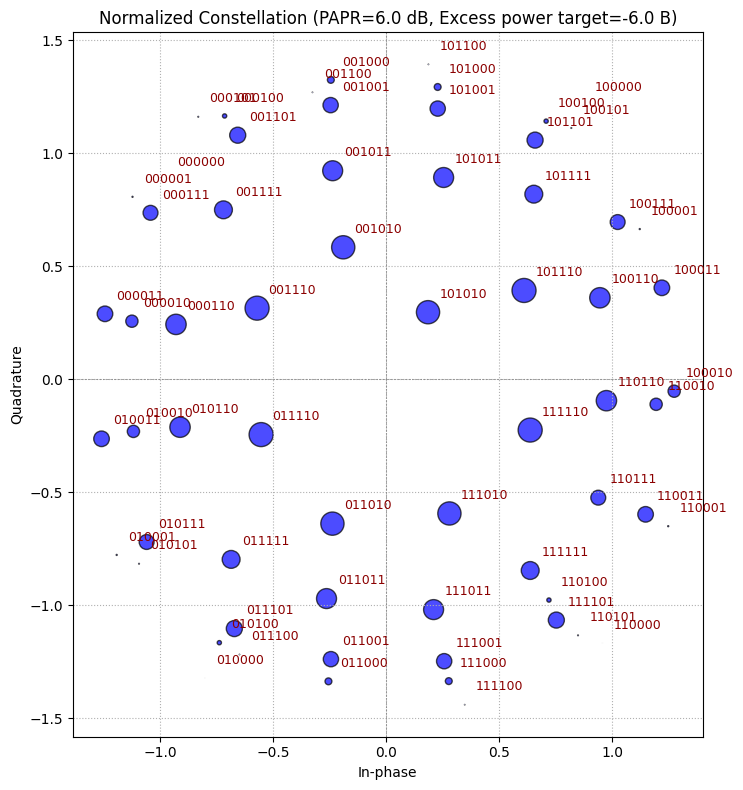

In [41]:
with tf.GradientTape(persistent=False) as tape:
#     tape.watch(model.trainable_variables)  # Ensure variables are watched if needed, but no gradients will be calculated
    _,_,_,shaping_probs,_ = model(No)


# Define constellation points (complex numbers)
points = model.modulator.constellation_real.numpy()+ 1j*model.modulator.constellation_imag.numpy()

# Define probabilities for each point
probabilities = shaping_probs.numpy()

# plt.savefig('const.pdf')

# Normalize the constellation
normalized_points = normalize_constellation(points, probabilities)

title_plot = f"Normalized Constellation (PAPR={papr_threshold_db} dB, Excess power target={excess_power_target} B)"
# Plot the constellation
plot_constellation_wlabels(normalized_points, probabilities, title_plot)
file_name = f"PAPR_{papr_threshold_db}_target_{excess_power_target}"
print(probabilities)
print(file_name)

[[0.00045056 0.00161766 0.00743757 0.01046399 0.00524043 0.01105734
  0.01825285 0.01811821 0.00791649 0.01880805 0.03618545 0.02892231
  0.01048142 0.0180157  0.03231501 0.02471696 0.00045056 0.00161766
  0.00743757 0.01046399 0.00524043 0.01105734 0.01825285 0.01811821
  0.00791649 0.01880805 0.03618545 0.02892231 0.01048142 0.0180157
  0.03231501 0.02471696 0.00045056 0.00161766 0.00743757 0.01046399
  0.00524043 0.01105734 0.01825285 0.01811821 0.00791649 0.01880805
  0.03618545 0.02892231 0.01048142 0.0180157  0.03231501 0.02471696
  0.00045056 0.00161766 0.00743757 0.01046399 0.00524043 0.01105734
  0.01825285 0.01811821 0.00791649 0.01880805 0.03618545 0.02892231
  0.01048142 0.0180157  0.03231501 0.02471696]]
PAPR_7.0_target_-6.0


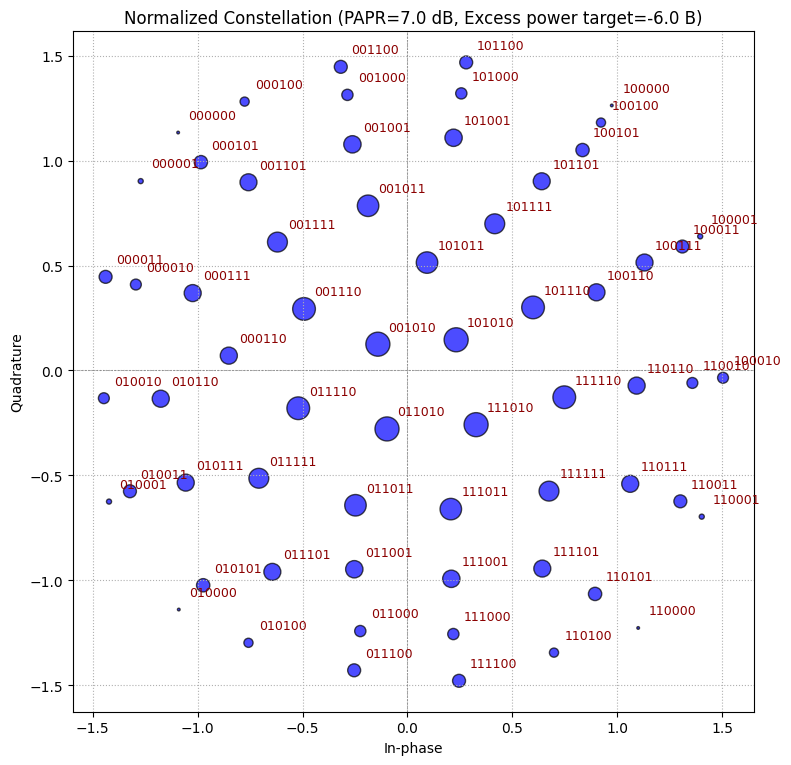

In [37]:
with tf.GradientTape(persistent=False) as tape:
#     tape.watch(model.trainable_variables)  # Ensure variables are watched if needed, but no gradients will be calculated
    _,_,_,shaping_probs,_ = model(No)


# Define constellation points (complex numbers)
points = model.modulator.constellation_real.numpy()+ 1j*model.modulator.constellation_imag.numpy()

# Define probabilities for each point
probabilities = shaping_probs.numpy()

# plt.savefig('const.pdf')

# Normalize the constellation
normalized_points = normalize_constellation(points, probabilities)

title_plot = f"Normalized Constellation (PAPR={papr_threshold_db} dB, Excess power target={excess_power_target} B)"
# Plot the constellation
plot_constellation_wlabels(normalized_points, probabilities, title_plot)
file_name = f"PAPR_{papr_threshold_db}_target_{excess_power_target}"
print(probabilities)
print(file_name)

[[0.00580007 0.00742622 0.00911532 0.0088395  0.00691191 0.010988
  0.02044792 0.01588115 0.00928103 0.02051033 0.03192843 0.02759723
  0.00902291 0.01547913 0.02767573 0.02309512 0.00580007 0.00742622
  0.00911532 0.0088395  0.00691191 0.010988   0.02044792 0.01588115
  0.00928103 0.02051033 0.03192843 0.02759723 0.00902291 0.01547913
  0.02767573 0.02309512 0.00580007 0.00742622 0.00911532 0.0088395
  0.00691191 0.010988   0.02044792 0.01588115 0.00928103 0.02051033
  0.03192843 0.02759723 0.00902291 0.01547913 0.02767573 0.02309512
  0.00580007 0.00742622 0.00911532 0.0088395  0.00691191 0.010988
  0.02044792 0.01588115 0.00928103 0.02051033 0.03192843 0.02759723
  0.00902291 0.01547913 0.02767573 0.02309512]]
PAPR_6.5_target_-4.0


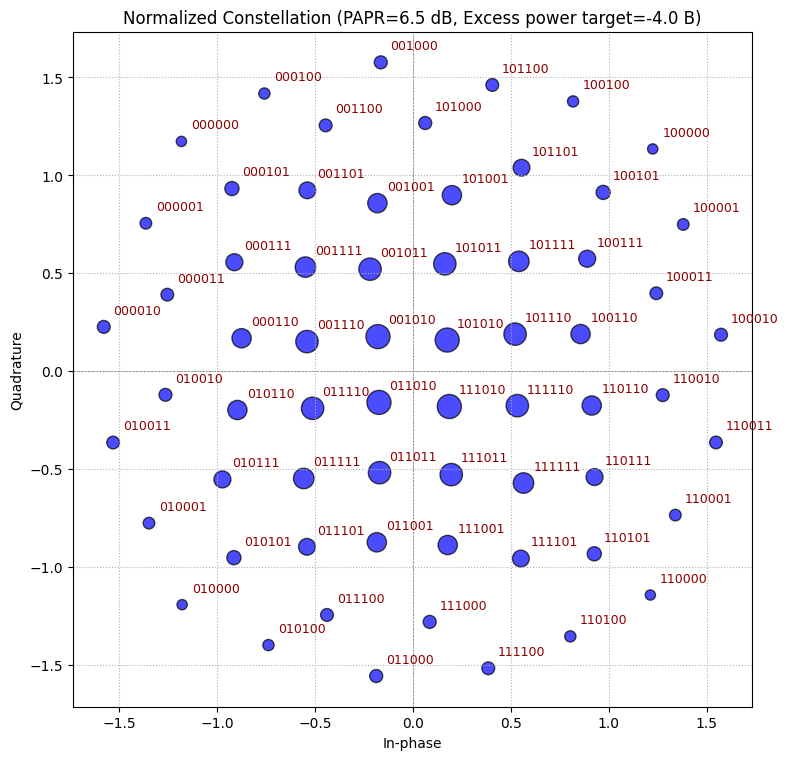

In [52]:
with tf.GradientTape(persistent=False) as tape:
#     tape.watch(model.trainable_variables)  # Ensure variables are watched if needed, but no gradients will be calculated
    _,_,_,shaping_probs = model(No)


# Define constellation points (complex numbers)
points = model.modulator.constellation_real.numpy()+ 1j*model.modulator.constellation_imag.numpy()

# Define probabilities for each point
probabilities = shaping_probs.numpy()

# plt.savefig('const.pdf')

# Normalize the constellation
normalized_points = normalize_constellation(points, probabilities)

title_plot = f"Normalized Constellation (PAPR={papr_threshold_db} dB, Excess power target={excess_power_target} B)"
# Plot the constellation
plot_constellation_wlabels(normalized_points, probabilities, title_plot)
file_name = f"PAPR_{papr_threshold_db}_target_{excess_power_target}"
print(probabilities)
print(file_name)

[[0.00744225 0.00780359 0.00773903 0.0077018  0.00798617 0.0133611
  0.01552091 0.01552145 0.00792664 0.01603401 0.03805894 0.02849483
  0.00802589 0.01563437 0.02782616 0.02492285 0.00744225 0.00780359
  0.00773903 0.0077018  0.00798617 0.0133611  0.01552091 0.01552145
  0.00792664 0.01603401 0.03805894 0.02849483 0.00802589 0.01563437
  0.02782616 0.02492285 0.00744225 0.00780359 0.00773903 0.0077018
  0.00798617 0.0133611  0.01552091 0.01552145 0.00792664 0.01603401
  0.03805894 0.02849483 0.00802589 0.01563437 0.02782616 0.02492285
  0.00744225 0.00780359 0.00773903 0.0077018  0.00798617 0.0133611
  0.01552091 0.01552145 0.00792664 0.01603401 0.03805894 0.02849483
  0.00802589 0.01563437 0.02782616 0.02492285]]
PAPR_7.0_target_-10


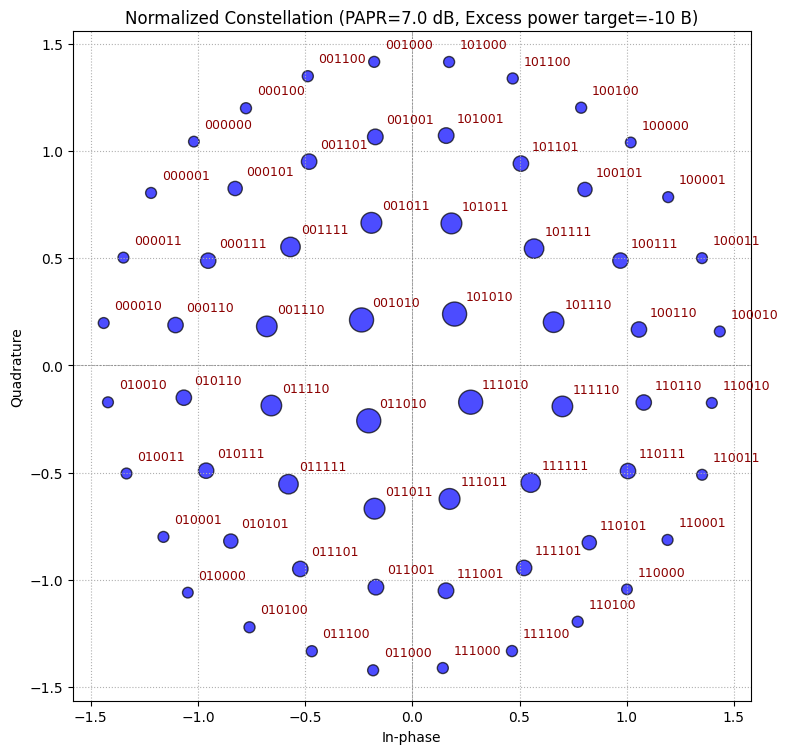

In [32]:
with tf.GradientTape(persistent=False) as tape:
#     tape.watch(model.trainable_variables)  # Ensure variables are watched if needed, but no gradients will be calculated
    _,_,_,shaping_probs = model(No)


# Define constellation points (complex numbers)
points = model.modulator.constellation_real.numpy()+ 1j*model.modulator.constellation_imag.numpy()

# Define probabilities for each point
probabilities = shaping_probs.numpy()

# plt.savefig('const.pdf')

# Normalize the constellation
normalized_points = normalize_constellation(points, probabilities)

title_plot = f"Normalized Constellation (PAPR={papr_threshold_db} dB, Excess power target={excess_power_target} B)"
# Plot the constellation
plot_constellation_wlabels(normalized_points, probabilities, title_plot)
file_name = f"PAPR_{papr_threshold_db}_target_{excess_power_target}"
print(probabilities)
print(file_name)

[[0.00840728 0.00890415 0.01452073 0.01004177 0.00818751 0.01318392
  0.01907451 0.01708065 0.01226854 0.01935609 0.02419078 0.02253234
  0.01262765 0.01676831 0.02243739 0.02041836 0.00840728 0.00890415
  0.01452073 0.01004177 0.00818751 0.01318392 0.01907451 0.01708065
  0.01226854 0.01935609 0.02419078 0.02253234 0.01262765 0.01676831
  0.02243739 0.02041836 0.00840728 0.00890415 0.01452073 0.01004177
  0.00818751 0.01318392 0.01907451 0.01708065 0.01226854 0.01935609
  0.02419078 0.02253234 0.01262765 0.01676831 0.02243739 0.02041836
  0.00840728 0.00890415 0.01452073 0.01004177 0.00818751 0.01318392
  0.01907451 0.01708065 0.01226854 0.01935609 0.02419078 0.02253234
  0.01262765 0.01676831 0.02243739 0.02041836]]
PAPR_8.0_target_-10


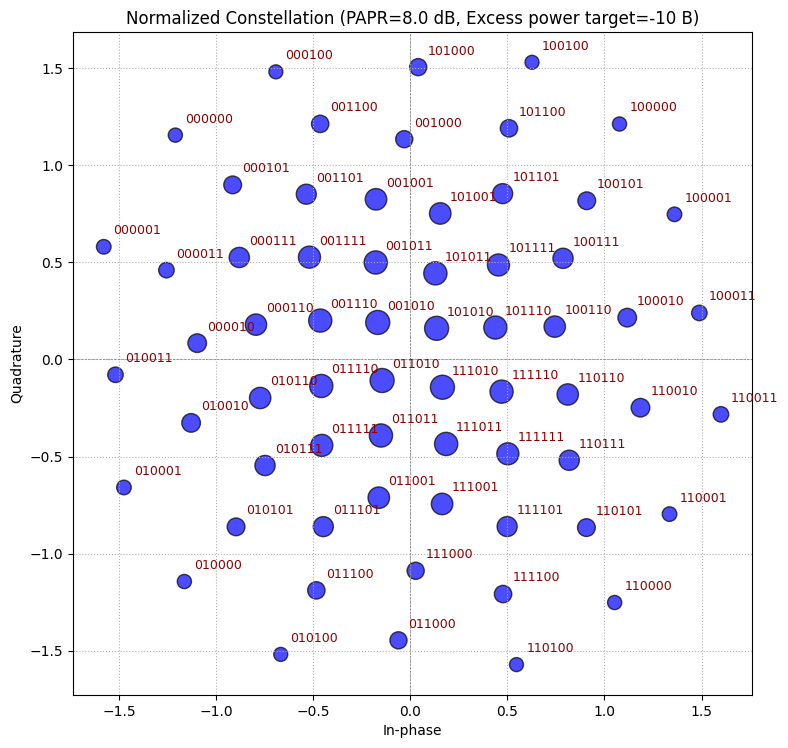

In [25]:
with tf.GradientTape(persistent=False) as tape:
#     tape.watch(model.trainable_variables)  # Ensure variables are watched if needed, but no gradients will be calculated
    _,_,_,shaping_probs = model(No)


# Define constellation points (complex numbers)
points = model.modulator.constellation_real.numpy()+ 1j*model.modulator.constellation_imag.numpy()

# Define probabilities for each point
probabilities = shaping_probs.numpy()

# plt.savefig('const.pdf')

# Normalize the constellation
normalized_points = normalize_constellation(points, probabilities)

title_plot = f"Normalized Constellation (PAPR={papr_threshold_db} dB, Excess power target={excess_power_target} B)"
# Plot the constellation
plot_constellation_wlabels(normalized_points, probabilities, title_plot)
file_name = f"PAPR_{papr_threshold_db}_target_{excess_power_target}"
print(probabilities)
print(file_name)

[[0.01194113 0.0121368  0.01177788 0.01209436 0.01210863 0.01377008
  0.01596701 0.01577005 0.01188698 0.01595242 0.02606357 0.02174469
  0.01199312 0.0152044  0.02176455 0.0198243  0.01194113 0.0121368
  0.01177788 0.01209436 0.01210863 0.01377008 0.01596701 0.01577005
  0.01188698 0.01595242 0.02606357 0.02174469 0.01199312 0.0152044
  0.02176455 0.0198243  0.01194113 0.0121368  0.01177788 0.01209436
  0.01210863 0.01377008 0.01596701 0.01577005 0.01188698 0.01595242
  0.02606357 0.02174469 0.01199312 0.0152044  0.02176455 0.0198243
  0.01194113 0.0121368  0.01177788 0.01209436 0.01210863 0.01377008
  0.01596701 0.01577005 0.01188698 0.01595242 0.02606357 0.02174469
  0.01199312 0.0152044  0.02176455 0.0198243 ]]
snr_15_PAPR_6.0_target_-10


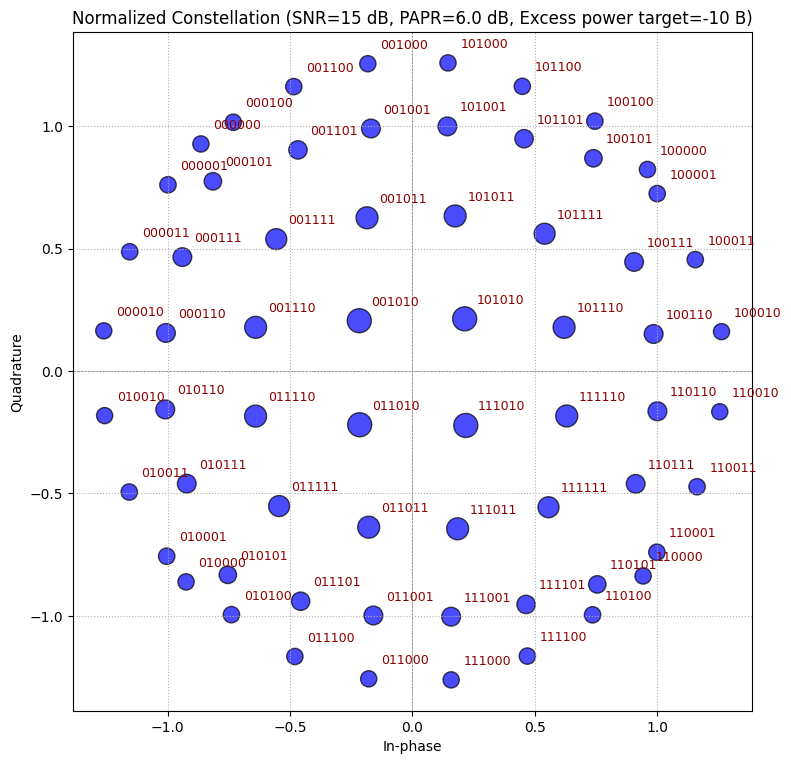

In [47]:
with tf.GradientTape(persistent=False) as tape:
#     tape.watch(model.trainable_variables)  # Ensure variables are watched if needed, but no gradients will be calculated
    _,_,_,shaping_probs = model(No)


# Define constellation points (complex numbers)
points = model.modulator.constellation_real.numpy()+ 1j*model.modulator.constellation_imag.numpy()

# Define probabilities for each point
probabilities = shaping_probs.numpy()

# plt.savefig('const.pdf')

# Normalize the constellation
normalized_points = normalize_constellation(points, probabilities)

title_plot = f"Normalized Constellation (SNR={snr_db} dB, PAPR={papr_threshold_db} dB, Excess power target={excess_power_target} B)"
# Plot the constellation
plot_constellation_wlabels(normalized_points, probabilities, title_plot)
file_name = f"snr_{snr_db}_PAPR_{papr_threshold_db}_target_{excess_power_target}"
print(probabilities)
print(file_name)

[[0.0134172  0.01393307 0.01372442 0.01358674 0.01387807 0.01556055
  0.01602791 0.01623357 0.01372111 0.01605643 0.01962569 0.0183065
  0.01360306 0.01624033 0.01833444 0.0177509  0.0134172  0.01393307
  0.01372442 0.01358674 0.01387807 0.01556055 0.01602791 0.01623357
  0.01372111 0.01605643 0.01962569 0.0183065  0.01360306 0.01624033
  0.01833444 0.0177509  0.0134172  0.01393307 0.01372442 0.01358674
  0.01387807 0.01556055 0.01602791 0.01623357 0.01372111 0.01605643
  0.01962569 0.0183065  0.01360306 0.01624033 0.01833444 0.0177509
  0.0134172  0.01393307 0.01372442 0.01358674 0.01387807 0.01556055
  0.01602791 0.01623357 0.01372111 0.01605643 0.01962569 0.0183065
  0.01360306 0.01624033 0.01833444 0.0177509 ]]
snr_15_PAPR_6.0_target_-10


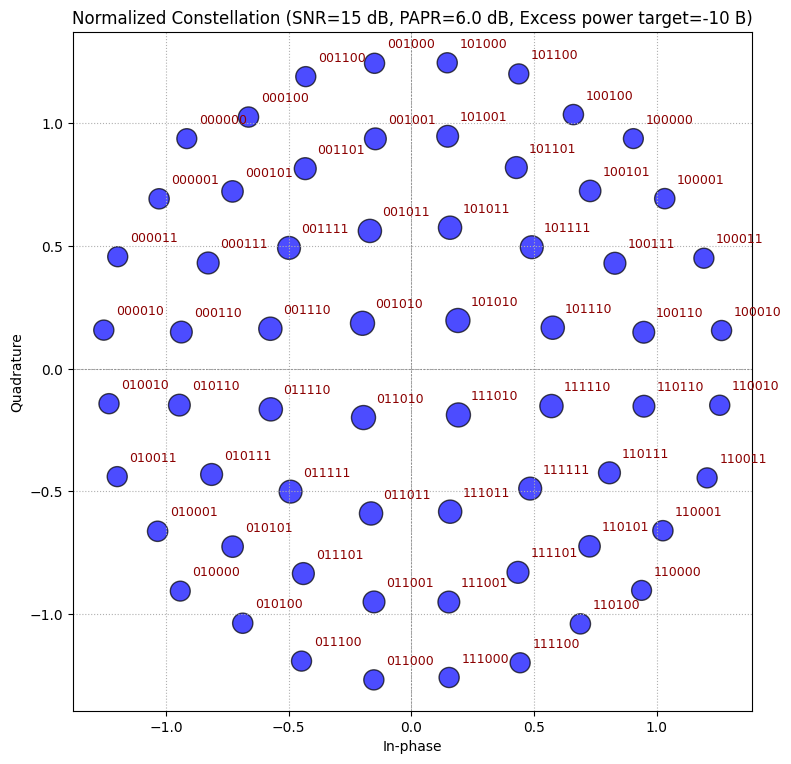

In [33]:
with tf.GradientTape(persistent=False) as tape:
#     tape.watch(model.trainable_variables)  # Ensure variables are watched if needed, but no gradients will be calculated
    _,_,_,shaping_probs = model(No)


# Define constellation points (complex numbers)
points = model.modulator.constellation_real.numpy()+ 1j*model.modulator.constellation_imag.numpy()

# Define probabilities for each point
probabilities = shaping_probs.numpy()

# plt.savefig('const.pdf')

# Normalize the constellation
normalized_points = normalize_constellation(points, probabilities)

title_plot = f"Normalized Constellation (SNR={snr_db} dB, PAPR={papr_threshold_db} dB, Excess power target={excess_power_target} B)"
# Plot the constellation
plot_constellation_wlabels(normalized_points, probabilities, title_plot)
file_name = f"snr_{snr_db}_PAPR_{papr_threshold_db}_target_{excess_power_target}"
print(probabilities)
print(file_name)


### Training for several SNR and PAPR values

In [62]:

def run_experiment(snr_db, papr_threshold_db):
    print(f"\n===== Running SNR={snr_db} dB | PAPR={papr_threshold_db} dB =====\n")

    ebno_db = tf.random.uniform(shape=[batch_size], minval=8.0, maxval=16.0)
    No_ = sn.phy.utils.ebnodb2no(ebno_db, num_bits_per_symbol=bits_per_symbol, coderate=1)
    No_ = tf.expand_dims(No_, axis=-1)


    # No_ = tf.convert_to_tensor(1/(10**(snr_db/10)),tf.float32)
    papr_threshold_ = tf.math.pow(10.0, papr_threshold_db / 10.0)
    excess_power_target_ = -6.0 #B

    lambd_papr = tf.Variable(tf.constant(0.0, tf.float32), trainable=False, dtype=tf.float32)
    mu = tf.Variable(0.01, trainable=False, dtype=tf.float32)
    step = tf.constant(0, tf.int32)

    for i in range(10):
        if i == 0:
            num_it = 500
        else:
            num_it = 35
        c_excess_power, step = _inner_loop(lambd_papr, mu, step,
                                           num_it, excess_power_target_,
                                           papr_threshold_, No_)

        # Update Lagrange multipliers
        tf.print('-------------------------------------------------------')
        tf.print('-------------------------------------------------------')
        tf.print('Progress ',i,' % ','c_excess_power',c_excess_power,'lambd_papr',lambd_papr,'mu',mu)
        tf.print('-------------------------------------------------------')
        tf.print('-------------------------------------------------------')
        lambd_papr = lambd_papr - mu * c_excess_power

        # Update penalty parameter
        mu = mu*1.003

    # ------------------
    # Save constellation
    # ------------------
    with tf.GradientTape() as tape:
        _, _, _, shaping_probs,_ = model(No_)

    points = (
        model.modulator.constellation_real.numpy()
        + 1j * model.modulator.constellation_imag.numpy()
    )
    probs = shaping_probs.numpy()

    normalized_points = normalize_constellation(points, probs)

    exp_name = f"snr_{snr_db}_papr_{papr_threshold_db}"
    # np.save(f"{RESULTS_DIR}/{exp_name}_points.npy", normalized_points)
    # np.save(f"{RESULTS_DIR}/{exp_name}_probs.npy", probs)

    plt.figure()
    plot_constellation_wlabels(
        normalized_points,
        probs,
        f"PAPR={papr_threshold_db} dB"
    )
    plt.savefig(f"{RESULTS_DIR}/{exp_name}_constellation.png")
    plt.close()

    # ------------------
    # Compute & save CCDF
    # ------------------
    powers = tf.reshape(
        model.compute_power_to_average_power_samples(), [-1]
    )
    powers_db = 10 * tf.math.log(powers + 1e-12) / tf.math.log(10.)

    x_sorted = np.sort(powers_db.numpy())
    ccdf = 1.0 - np.arange(1, len(x_sorted) + 1) / len(x_sorted)

    np.savez(
        f"{RESULTS_DIR}/{exp_name}.npz",
        snr_db=snr_db,
        papr_db=papr_threshold_db,
        constellation_points=normalized_points,
        constellation_probabilities=probs,
        ccdf_x_db=x_sorted,
        ccdf_y=ccdf
    )


    # np.save(f"{RESULTS_DIR}/{exp_name}_ccdf_x.npy", x_sorted)
    # np.save(f"{RESULTS_DIR}/{exp_name}_ccdf_y.npy", ccdf)


    print(f"Finished {exp_name}")



===== Running SNR=13 dB | PAPR=6.0 dB =====

Iteration 0 L -0.606898785 loss -0.635343432 loss_ordinary 5.35802364 entropy_value 5.99336672 glob_norm 10.9895535
Iteration 50 L -1.77966785 loss -1.84307957 loss_ordinary 4.0794692 entropy_value 5.92254877 glob_norm 2.05809879
Iteration 100 L -2.35514092 loss -2.45163679 loss_ordinary 3.32130694 entropy_value 5.7729435 glob_norm 23.7075882
Iteration 150 L -2.55143952 loss -2.64653015 loss_ordinary 3.10986185 entropy_value 5.756392 glob_norm 24.5825939
Iteration 200 L -2.835747 loss -2.93692565 loss_ordinary 2.76305509 entropy_value 5.69998074 glob_norm 2.2748909
Iteration 250 L -2.57862306 loss -2.6798048 loss_ordinary 3.02819967 entropy_value 5.70800447 glob_norm 2.31170344
Iteration 300 L -2.60390019 loss -2.70570612 loss_ordinary 3.01812625 entropy_value 5.72383213 glob_norm 2.1878438
Iteration 350 L -2.85527611 loss -2.96141386 loss_ordinary 2.71852589 entropy_value 5.67993975 glob_norm 2.6599009
Iteration 400 L -2.88765097 loss -2.9

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

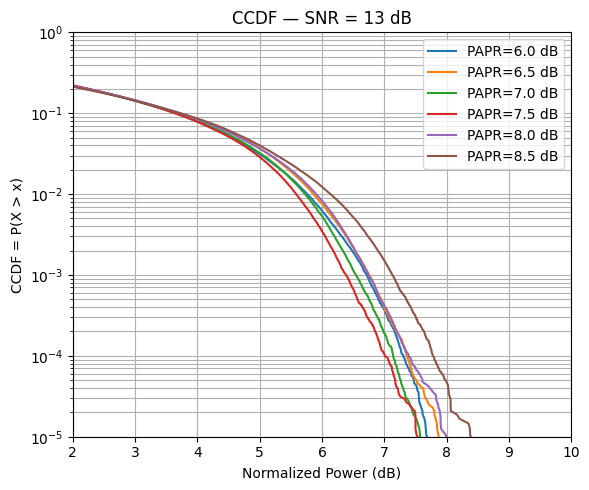

In [63]:
snr_list = [13]
papr_list = [6.0, 6.5, 7.0, 7.5, 8.0, 8.5]

N = 64  # Number of classes (symbols)
bits_per_symbol = int(np.log2(N))
parity_k = 2
use_upsampling_filtering = True  # Remove 'false' this after testing without upsampling and filtering
constellation = symbol_points_qam64

tau = 10
# snr_db = 15


# Batch size
batch_size = 10
papr_batch_size = 30
block_size = 4096-32*4

# No = tf.convert_to_tensor(1/(10**(snr_db/10)),tf.float32)
ebno_db = tf.random.uniform(shape=[batch_size], minval=8.0, maxval=16.0)
No_ = sn.phy.utils.ebnodb2no(ebno_db, num_bits_per_symbol=bits_per_symbol, coderate=1)
No_ = tf.expand_dims(No_, axis=-1)


model = EndToEndSystem_bitwise(N, constellation, papr_batch_size,
                                batch_size, block_size,
                               bits_per_symbol, parity_k,
                               use_upsampling_filtering, tau)
_,_,_,_,_ = model(No_)
initial_weights = model.get_weights()

optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)

RESULTS_DIR = "results_pn_prob_aware"
os.makedirs(RESULTS_DIR, exist_ok=True)


for snr_db in snr_list:
    for papr_db in papr_list:
        print('-------------------------------------------------------')
        print('PAPR :',papr_db,' dB')
        print('-------------------------------------------------------')
        model.set_weights(initial_weights)
        optimizer = tf.keras.optimizers.Adam(0.001)
        run_experiment(snr_db, papr_db)
        tf.keras.backend.clear_session()
        gc.collect()

print("ALL EXPERIMENTS FINISHED")

for snr_db in snr_list:

    plt.figure(figsize=(6, 5))

    for papr_db in papr_list:
        exp_name = f"snr_{snr_db}_papr_{papr_db}"
        data = np.load(f"{RESULTS_DIR}/{exp_name}.npz")

        x = data["ccdf_x_db"]
        y = data["ccdf_y"]

        plt.plot(x, y, label=f"PAPR={papr_db} dB")

    plt.yscale("log")
    plt.xlabel("Normalized Power (dB)")
    plt.ylabel("CCDF = P(X > x)")
    plt.title(f"CCDF — SNR = {snr_db} dB")
    plt.grid(True, which="both")
    plt.xlim(2, 10)
    plt.ylim(1e-5, 1)
    plt.legend()

    plt.tight_layout()
    plt.savefig(f"{RESULTS_DIR}/ccdf_snr_{snr_db}.png", dpi=300)
    # plt.show()


### Plotting saved data

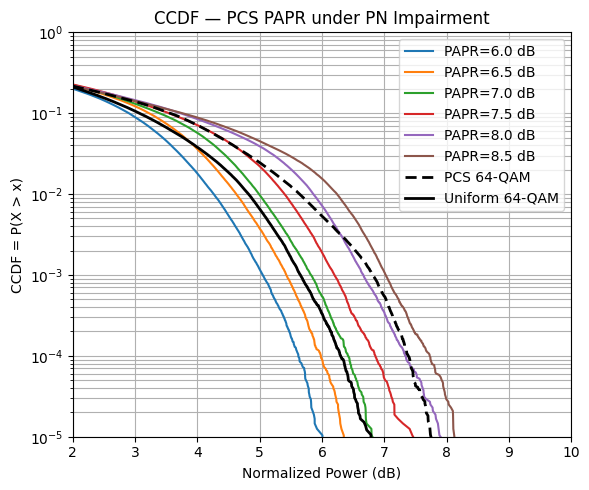

In [22]:
RESULTS_DIR = "results_pn_prob_aware"

snr_list = [13]
papr_list = [6.0, 6.5, 7.0, 7.5, 8.0, 8.5]



for snr_db in snr_list:

    plt.figure(figsize=(6, 5))

    for papr_db in papr_list:
        exp_name = f"snr_{snr_db}_papr_{papr_db}"
        data = np.load(f"{RESULTS_DIR}/{exp_name}.npz")

        x = data["ccdf_x_db"]
        y = data["ccdf_y"]

        plt.plot(x, y, label=f"PAPR={papr_db} dB")

    # Probabilistically shaped QAM-64 (long dashed black)
    data = np.load(f"{RESULTS_DIR}/QAM_prob_shaped.npz")
    x = data["ccdf_x_db"]
    y = data["ccdf_y"]
    plt.plot(
        x, y,
        color="black",
        linestyle=(0, (4, 2)),   # long dash pattern
        linewidth=2,
        label="PCS 64-QAM"
    )

    # Uniform QAM-64 (solid black)
    data = np.load(f"{RESULTS_DIR}/QAM64_CCDF.npz")
    x = data["ccdf_x_db"]
    y = data["ccdf_y"]
    plt.plot(
        x, y,
        color="black",
        linestyle="-",            # solid line
        linewidth=2,
        label="Uniform 64-QAM"
    )

    plt.yscale("log")
    plt.xlabel("Normalized Power (dB)")
    plt.ylabel("CCDF = P(X > x)")
    plt.title(f"CCDF — PCS PAPR under PN Impairment")
    plt.grid(True, which="both")
    plt.xlim(2, 10)
    plt.ylim(1e-5, 1)
    plt.legend()

    plt.tight_layout()
    plt.savefig(f"{RESULTS_DIR}/ccdf_snr_{snr_db}.png", dpi=300)
    # plt.show()


### Plotting a single plot

In [ ]:
powers_ccdf = tf.reshape(model.compute_power_to_average_power_samples(),[-1])
powers_ccdf_db = 10*tf.math.log(powers_ccdf + 1e-12) / tf.math.log(10.)

# Sort data
x_sorted = np.sort(powers_ccdf_db.numpy())

# CCDF values
ccdf = 1.0 - np.arange(1, len(x_sorted) + 1) / len(x_sorted)

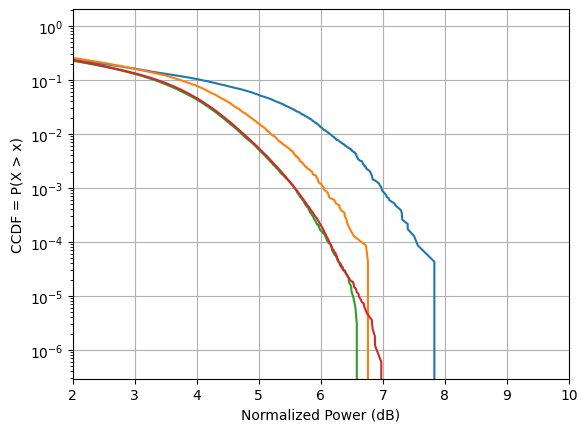

In [93]:
# Plot
plt.figure()
plt.plot(x_sorted, ccdf)
# plt.plot(x_sorted2, ccdf2)
# plt.plot(x_sorted3, ccdf3)
# plt.plot(x_sorted4, ccdf4)
plt.xlabel("Normalized Power (dB)")
plt.xlim(2,10)
plt.ylabel("CCDF = P(X > x)")
plt.yscale("log")   # optional, very common
plt.grid(True)
plt.show()


In [49]:
# Checking trainable parameters of the model

for v in model.trainable_weights:
    print(v.path, v.shape)

end_to_end_system_bitwise_11/sampling_mechanism_10/dense_38/kernel (1, 128)
end_to_end_system_bitwise_11/sampling_mechanism_10/dense_38/bias (128,)
end_to_end_system_bitwise_11/sampling_mechanism_10/dense_39/kernel (128, 16)
end_to_end_system_bitwise_11/sampling_mechanism_10/dense_39/bias (16,)
end_to_end_system_bitwise_11/modulator_6/constellation_real (64,)
end_to_end_system_bitwise_11/modulator_6/constellation_imag (64,)
end_to_end_system_bitwise_11/demodulator_bitwise_6/dense_40/kernel (3, 128)
end_to_end_system_bitwise_11/demodulator_bitwise_6/dense_40/bias (128,)
end_to_end_system_bitwise_11/demodulator_bitwise_6/dense_41/kernel (128, 128)
end_to_end_system_bitwise_11/demodulator_bitwise_6/dense_41/bias (128,)
end_to_end_system_bitwise_11/demodulator_bitwise_6/dense_42/kernel (128, 6)
end_to_end_system_bitwise_11/demodulator_bitwise_6/dense_42/bias (6,)
